# Exploratory Data Analysis — `Experiment3/Experiments/DATA/`

This notebook explores the **raw** experiment data (participants, condition
assignment, eHMI metadata, and per-participant questionnaire responses) — the
inputs to `../ExpDataAnalyze/preprocess_data.py`, upstream of the processed
`database.xlsx` consumed by the `Models/` recommender pipeline.

Unlike `preprocess_data.py`, this notebook loads **all 35** response files
(it does not silently drop `C3`, `C15`, `C25`, `C30`, `C31`) so the exclusion
list used by the modeling pipeline can be audited here instead of assumed.

Sections:
1. Participant demographics & personality
2. eHMI condition metadata
3. Condition / assignment structure
4. Survey response distributions
5. Data quality / exclusion audit
6. Takeaways


In [1]:
import sys
sys.path.insert(0, ".")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

import eda_utils as eu

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 40)


In [2]:
participants = eu.load_participants()
condition = eu.load_condition()
ehmi = eu.load_ehmi()
responses = eu.load_all_responses()
resp_long = eu.responses_long(responses)

print("participants:", participants.shape)
print("condition:", condition.shape)
print("ehmi:", ehmi.shape)
print("n response files:", len(responses))
print("resp_long:", resp_long.shape)


/home/namdp15/.local/lib/python3.10/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
/home/namdp15/.local/lib/python3.10/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Conditional Formatting extension is not supported and will be removed
  warn(msg)
/home/namdp15/.local/lib/python3.10/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
/home/namdp15/.local/lib/python3.10/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Conditional Formatting extension is not supported and will be removed
  warn(msg)
/home/namdp15/.local/lib/python3.10/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
/home/namdp15/.local/lib/python3.10/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Conditional Formatting extension is not support

participants: (36, 36)
condition: (31, 35)
ehmi: (51, 9)
n response files: 35
resp_long: (1089, 30)


/home/namdp15/.local/lib/python3.10/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
/home/namdp15/.local/lib/python3.10/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Conditional Formatting extension is not supported and will be removed
  warn(msg)
/home/namdp15/.local/lib/python3.10/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
/home/namdp15/.local/lib/python3.10/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Conditional Formatting extension is not supported and will be removed
  warn(msg)
/home/namdp15/.local/lib/python3.10/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
/home/namdp15/.local/lib/python3.10/site-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Conditional Formatting extension is not support

## 1. Participant demographics & personality

In [3]:
# Participants.xlsx carries a trailing "Total" summary row (Participant ID == "Total",
# every other field NaN) — it is not a real participant, so drop it before any analysis.
participants = participants[participants["Participant ID"] != "Total"].copy()
print(f"{len(participants)} participants after dropping the summary row")
participants[["Participant ID", "TestID", "Gender", "Nationality"]].head()


35 participants after dropping the summary row


,Participant ID,TestID,Gender,Nationality
0,P1,C0,Male,Vietnam
1,P2,C1,Male,Peru
2,P5,C2,Male,Malaysia
3,P3,C3,Male,France
4,P4,C4,Male,China


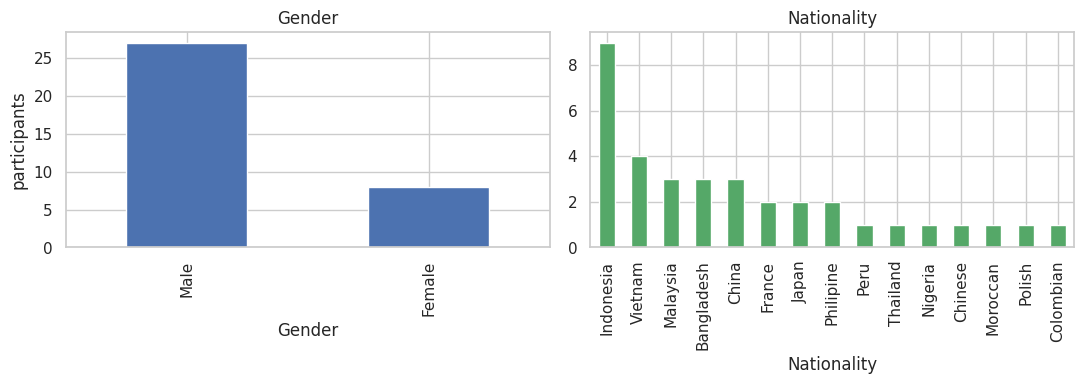

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
participants["Gender"].value_counts(dropna=False).plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set_title("Gender")
axes[0].set_ylabel("participants")

participants["Nationality"].value_counts(dropna=False).plot.bar(ax=axes[1], color="#55A868")
axes[1].set_title("Nationality")
axes[1].tick_params(axis="x", labelrotation=90)
fig.tight_layout()
eu.savefig(fig, "participant_demographics")
plt.show()


**Age:** `Participants.xlsx` (and every other raw file under `Experiments/DATA/`)
has no age/date-of-birth field — only `Participant ID`, `Student ID`, `Name`,
`Gender`, `Nationality`, `TestID`, and the TIPI columns. Age is not
collectable from this dataset; flagging this instead of fabricating a
distribution.


In [5]:
nationality_counts = participants["Nationality"].value_counts(dropna=False)
nationality_summary = pd.DataFrame({
    "n_participants": nationality_counts,
    "pct": (nationality_counts / len(participants) * 100).round(1),
})
nationality_summary.index.name = "nationality"
eu.save_table(nationality_summary.reset_index(), "nationality_distribution")
nationality_summary


,n_participants,pct
nationality,,
Indonesia,9,25.7
Vietnam,4,11.4
Malaysia,3,8.6
Bangladesh,3,8.6
China,3,8.6
France,2,5.7
Japan,2,5.7
Philipine,2,5.7
Peru,1,2.9


**Data quality note:** `Nationality` is free text, so `"China"` and
`"Chinese"` are recorded as two separate categories despite meaning the same
thing (likewise `"Philipine"` is a misspelling of "Philippines"). The counts
above are as-entered; merge these labels before treating nationality as a
clean categorical feature downstream.


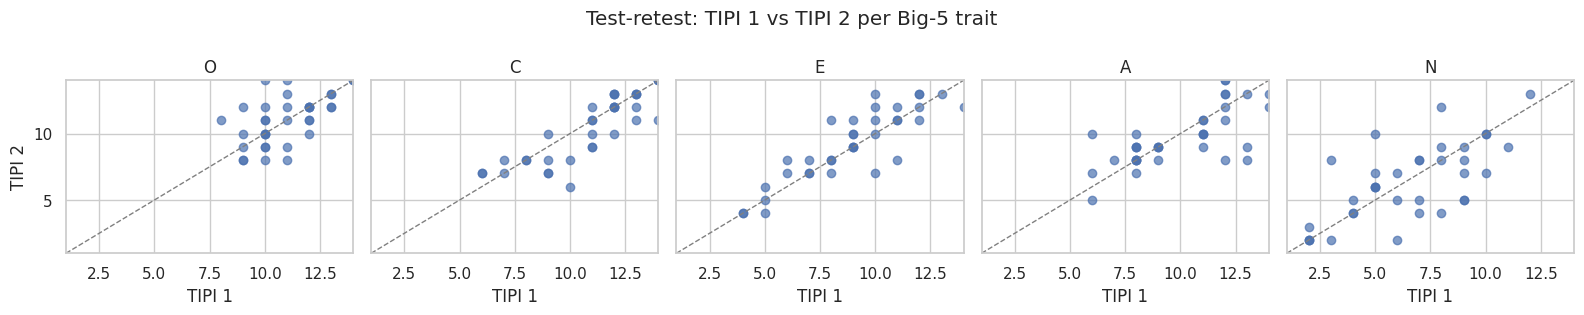

trait
O    0.577823
C    0.855727
E    0.873625
A    0.699343
N    0.682857
Name: pearson_r, dtype: float64

In [6]:
tipi_traits = ["O", "C", "E", "A", "N"]
tipi1_cols = [f"TIPI 1 {t}" for t in tipi_traits]
tipi2_cols = [f"TIPI 2 {t}" for t in tipi_traits]

fig, axes = plt.subplots(1, 5, figsize=(16, 3.2), sharey=True)
for ax, trait, c1, c2 in zip(axes, tipi_traits, tipi1_cols, tipi2_cols):
    ax.scatter(participants[c1], participants[c2], alpha=0.7)
    lims = [1, 14]
    ax.plot(lims, lims, ls="--", c="grey", lw=1)
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_title(trait)
    ax.set_xlabel("TIPI 1")
axes[0].set_ylabel("TIPI 2")
fig.suptitle("Test-retest: TIPI 1 vs TIPI 2 per Big-5 trait")
fig.tight_layout()
eu.savefig(fig, "tipi_test_retest_scatter")
plt.show()

retest_corr = pd.Series(
    {t: participants[c1].corr(participants[c2]) for t, c1, c2 in zip(tipi_traits, tipi1_cols, tipi2_cols)},
    name="pearson_r",
)
retest_corr.index.name = "trait"
eu.save_table(retest_corr.reset_index(), "tipi_test_retest_correlation")
retest_corr


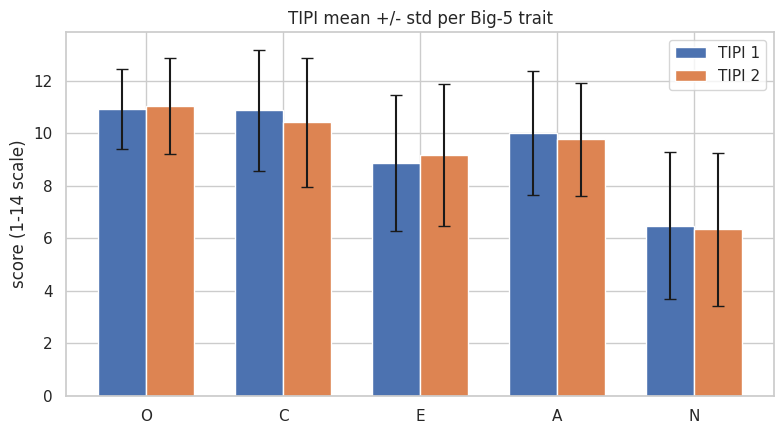

,tipi1_mean,tipi1_std,tipi2_mean,tipi2_std
trait,,,,
O,10.943,1.533,11.057,1.830
C,10.886,2.311,10.429,2.465
E,8.886,2.598,9.171,2.717
A,10.000,2.364,9.771,2.170
N,6.486,2.790,6.343,2.920


In [7]:
# Mean +/- std per Big-5 trait, for each TIPI administration (raw 1-14 item-sum scale).
tipi_summary = pd.DataFrame({
    "tipi1_mean": participants[tipi1_cols].mean().set_axis(tipi_traits),
    "tipi1_std": participants[tipi1_cols].std().set_axis(tipi_traits),
    "tipi2_mean": participants[tipi2_cols].mean().set_axis(tipi_traits),
    "tipi2_std": participants[tipi2_cols].std().set_axis(tipi_traits),
})
tipi_summary.index.name = "trait"
eu.save_table(tipi_summary.round(3).reset_index(), "tipi_summary_stats")

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(tipi_traits))
width = 0.35
ax.bar(x - width / 2, tipi_summary["tipi1_mean"], width, yerr=tipi_summary["tipi1_std"], capsize=4, label="TIPI 1")
ax.bar(x + width / 2, tipi_summary["tipi2_mean"], width, yerr=tipi_summary["tipi2_std"], capsize=4, label="TIPI 2")
ax.set_xticks(x)
ax.set_xticklabels(tipi_traits)
ax.set_ylabel("score (1-14 scale)")
ax.set_title("TIPI mean +/- std per Big-5 trait")
ax.legend()
fig.tight_layout()
eu.savefig(fig, "tipi_summary_stats")
plt.show()

tipi_summary.round(3)


## 2. eHMI condition metadata

50 experimental conditions + 1 control (99.T)


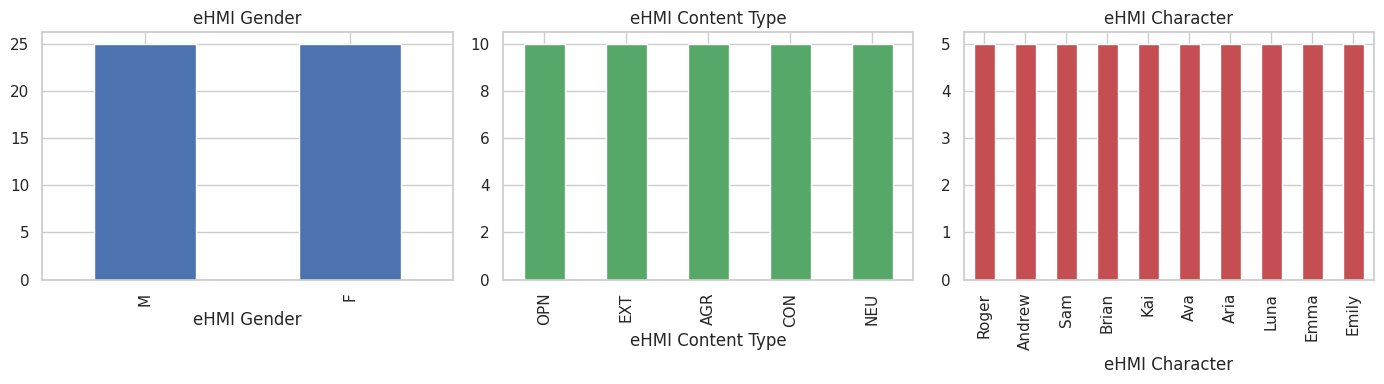

In [8]:
# Condition "99.T" (Content Type "CON") is a control/catch trial, not one of the
# 50 experimental eHMI voices — analyze it separately from the trait-content breakdown.
ehmi_experimental = ehmi[ehmi["Condition"] != "99.T"].copy()
print(f"{len(ehmi_experimental)} experimental conditions + 1 control (99.T)")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
ehmi_experimental["eHMI Gender"].value_counts().plot.bar(ax=axes[0], color="#4C72B0")
axes[0].set_title("eHMI Gender")
ehmi_experimental["eHMI Content Type"].value_counts().plot.bar(ax=axes[1], color="#55A868")
axes[1].set_title("eHMI Content Type")
ehmi_experimental["eHMI Character"].value_counts().plot.bar(ax=axes[2], color="#C44E52")
axes[2].set_title("eHMI Character")
axes[2].tick_params(axis="x", labelrotation=90)
fig.tight_layout()
eu.savefig(fig, "ehmi_metadata_balance")
plt.show()


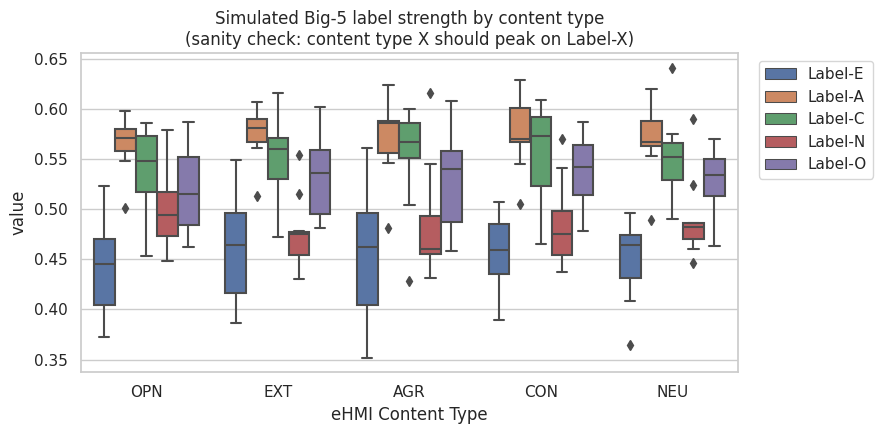

In [9]:
label_cols = ["Label-E", "Label-A", "Label-C", "Label-N", "Label-O"]
label_long = ehmi_experimental.melt(
    id_vars=["eHMI Content Type"], value_vars=label_cols, var_name="label", value_name="value"
)

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=label_long, x="eHMI Content Type", y="value", hue="label", ax=ax)
ax.set_title("Simulated Big-5 label strength by content type\n(sanity check: content type X should peak on Label-X)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
eu.savefig(fig, "ehmi_label_strength_by_content_type")
plt.show()


## 3. Condition / assignment structure

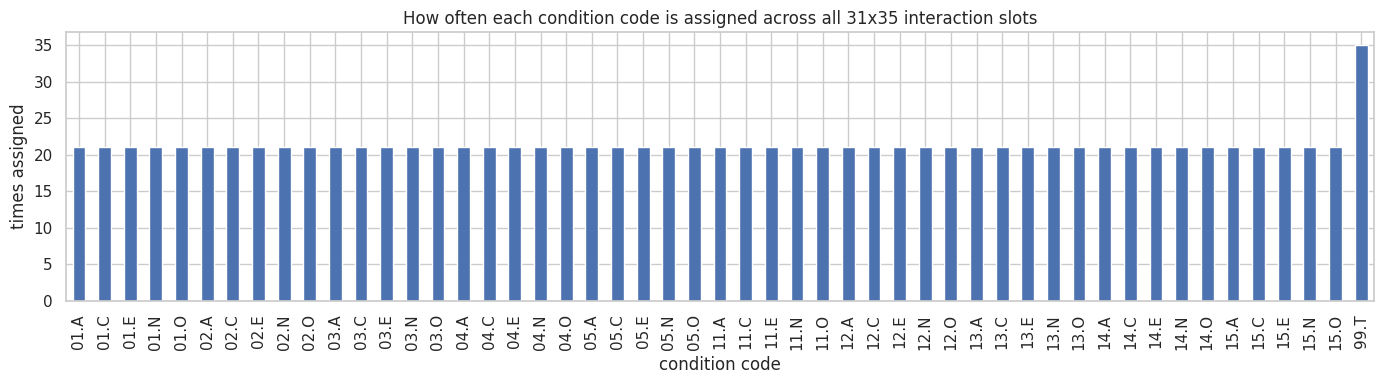

count    51.000000
mean     21.274510
std       1.960392
min      21.000000
25%      21.000000
50%      21.000000
75%      21.000000
max      35.000000
Name: count, dtype: float64

In [10]:
participant_cols = [c for c in condition.columns]
condition_counts = condition[participant_cols].values.ravel()
condition_counts = pd.Series(condition_counts).value_counts().sort_index()

fig, ax = plt.subplots(figsize=(14, 4))
condition_counts.plot.bar(ax=ax, color="#4C72B0")
ax.set_title("How often each condition code is assigned across all 31x35 interaction slots")
ax.set_xlabel("condition code")
ax.set_ylabel("times assigned")
fig.tight_layout()
eu.savefig(fig, "condition_assignment_frequency")
plt.show()

eu.save_table(condition_counts.rename_axis("condition_code").reset_index(name="n_assigned"), "condition_assignment_frequency")
condition_counts.describe()


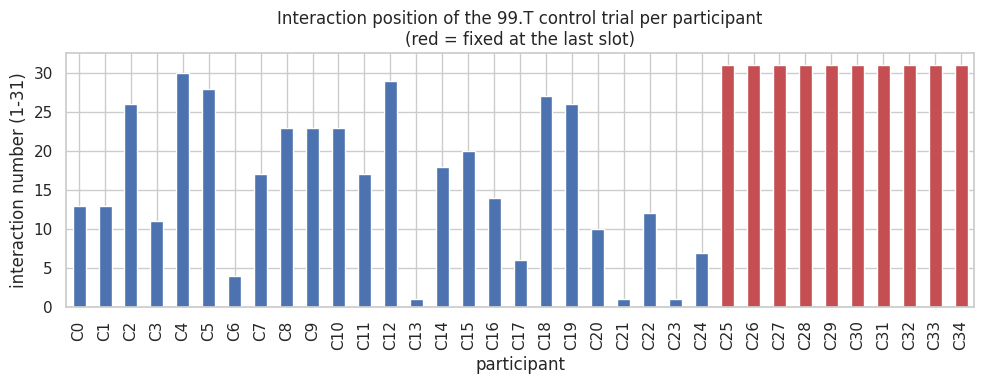

Participants with control trial fixed at the last interaction (31):
['C25', 'C26', 'C27', 'C28', 'C29', 'C30', 'C31', 'C32', 'C33', 'C34']


In [11]:
# Row (interaction-order) position of the 99.T control trial, per participant.
control_position = {}
for c in condition.columns:
    idx = condition.index[condition[c] == "99.T"]
    control_position[c] = int(idx[0]) + 1 if len(idx) else np.nan  # 1-based interaction number

control_pos = pd.Series(control_position, name="control_trial_interaction_number")
control_pos.index.name = "participant"

fig, ax = plt.subplots(figsize=(10, 4))
control_pos.plot.bar(ax=ax, color=["#C44E52" if v == 31 else "#4C72B0" for v in control_pos])
ax.set_title("Interaction position of the 99.T control trial per participant\n(red = fixed at the last slot)")
ax.set_ylabel("interaction number (1-31)")
fig.tight_layout()
eu.savefig(fig, "control_trial_position")
plt.show()

eu.save_table(control_pos.reset_index(), "control_trial_position")
print("Participants with control trial fixed at the last interaction (31):")
print(control_pos[control_pos == 31].index.tolist())


## 4. Survey response distributions

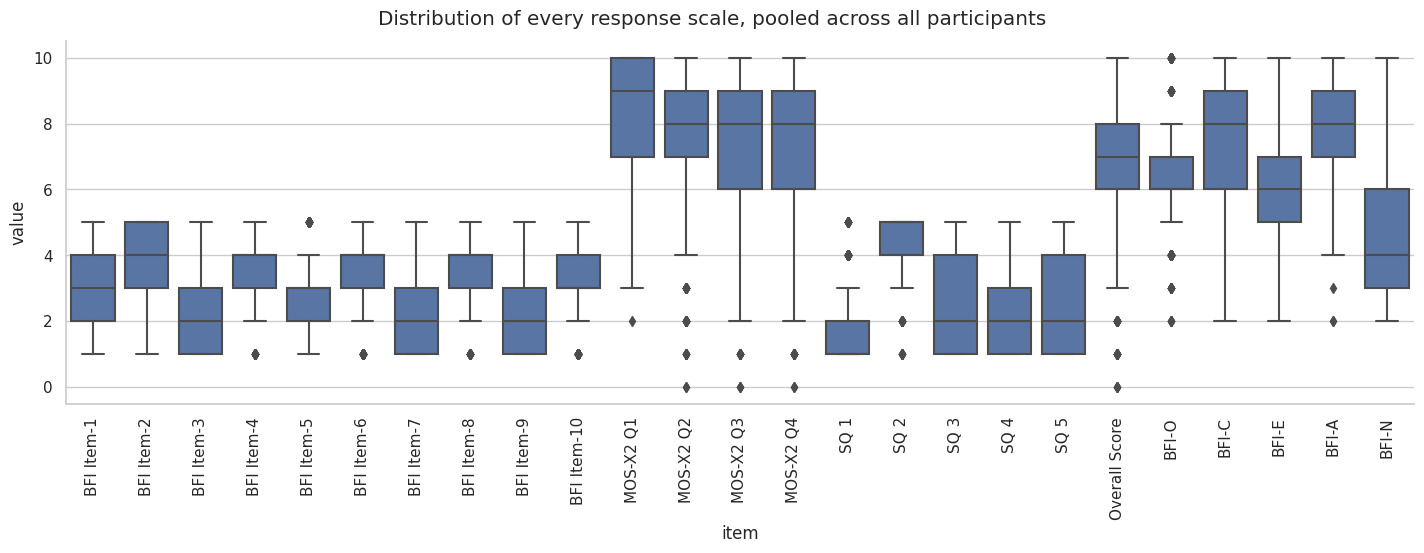

In [12]:
numeric_scale_cols = (
    [f"BFI Item-{i}" for i in range(1, 11)]
    + ["MOS-X2 Q1", "MOS-X2 Q2", "MOS-X2 Q3", "MOS-X2 Q4"]
    + [f"SQ {i}" for i in range(1, 6)]
    + ["Overall Score"]
    + ["BFI-O", "BFI-C", "BFI-E", "BFI-A", "BFI-N"]
)

# MOS-X2 Q1 contains a stray whitespace string in C3 (see Section 5) — coerce defensively.
resp_numeric = resp_long.copy()
for c in numeric_scale_cols:
    resp_numeric[c] = pd.to_numeric(resp_numeric[c], errors="coerce")

melted = resp_numeric.melt(id_vars=["participant"], value_vars=numeric_scale_cols, var_name="item", value_name="value")

g = sns.catplot(
    data=melted, x="item", y="value", kind="box",
    height=4.5, aspect=3.2, color="#4C72B0",
)
g.set_xticklabels(rotation=90)
g.fig.suptitle("Distribution of every response scale, pooled across all participants", y=1.03)
eu.savefig(g.fig, "response_scale_boxplots")
plt.show()


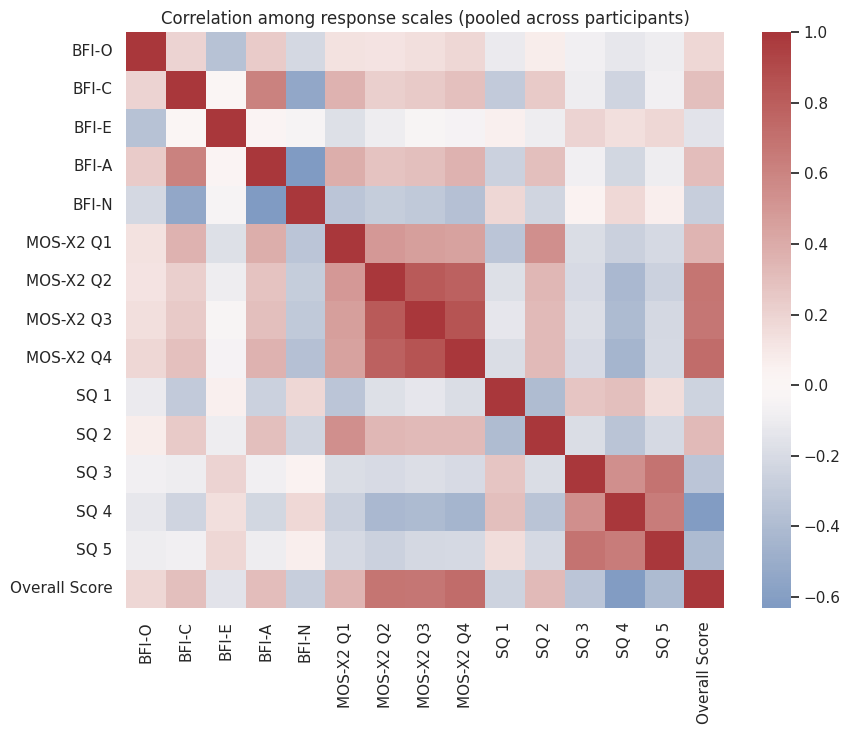

In [13]:
agg_cols = ["BFI-O", "BFI-C", "BFI-E", "BFI-A", "BFI-N", "MOS-X2 Q1", "MOS-X2 Q2", "MOS-X2 Q3", "MOS-X2 Q4",
            "SQ 1", "SQ 2", "SQ 3", "SQ 4", "SQ 5", "Overall Score"]
corr = resp_numeric[agg_cols].corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, cmap="vlag", center=0, annot=False, ax=ax)
ax.set_title("Correlation among response scales (pooled across participants)")
fig.tight_layout()
eu.savefig(fig, "response_scale_correlation")
plt.show()


In [14]:
# The Rank column is present in the schema but check whether it is ever populated.
n_rank_populated = resp_long["Rank"].notna().sum()
print(f"Rank populated in {n_rank_populated} / {len(resp_long)} response rows")


Rank populated in 0 / 1089 response rows


## 5. Data quality / exclusion audit

In [15]:
EXPECTED_ROWS = 31
row_counts = pd.Series({p: len(df) for p, df in responses.items()}, name="n_rows")
row_counts.index.name = "participant"
bad_row_count = row_counts[row_counts != EXPECTED_ROWS]
print(f"Expected {EXPECTED_ROWS} rows/interactions per participant.")
print("Files with a different row count (likely a trailing blank row):")
bad_row_count


Expected 31 rows/interactions per participant.
Files with a different row count (likely a trailing blank row):


participant
C31    32
C32    32
C33    32
C34    32
Name: n_rows, dtype: int64

In [16]:
missing_by_participant = {
    p: df.drop(columns=["Comment", "Rank"]).isna().sum().sum() for p, df in responses.items()
}
missing_by_participant = pd.Series(missing_by_participant, name="n_missing_cells")
missing_by_participant.index.name = "participant"
missing_by_participant.sort_values(ascending=False).head(10)


participant
C32    25
C33    25
C34    25
C31    25
C2      4
C0      4
C1      4
C4      4
C5      4
C6      4
Name: n_missing_cells, dtype: int64

In [17]:
# "Straight-lining": participants who barely vary their BFI-item ratings across the
# whole session are a common self-report data-quality red flag.
bfi_item_cols = [f"BFI Item-{i}" for i in range(1, 11)]
straightline_std = {
    p: pd.to_numeric(df[bfi_item_cols].stack(), errors="coerce").std() for p, df in responses.items()
}
straightline_std = pd.Series(straightline_std, name="bfi_item_std")
straightline_std.index.name = "participant"
straightline_std.sort_values().head(10)


participant
C23    0.598917
C32    0.674541
C28    0.782074
C24    0.823093
C14    0.845028
C27    0.944813
C26    0.947962
C11    0.956055
C12    0.978893
C10    0.981832
Name: bfi_item_std, dtype: float64

In [18]:
# Scan every response file for values that don't parse as numbers in columns that
# should be purely numeric (the modeling pipeline silently coerces/drops these).
non_numeric_report = []
for p, df in responses.items():
    for c in numeric_scale_cols:
        coerced = pd.to_numeric(df[c], errors="coerce")
        bad_mask = df[c].notna() & coerced.isna()
        if bad_mask.any():
            non_numeric_report.append(
                {"participant": p, "column": c, "n_bad": int(bad_mask.sum()), "bad_values": df.loc[bad_mask, c].tolist()}
            )
non_numeric_df = pd.DataFrame(non_numeric_report)
eu.save_table(non_numeric_df, "non_numeric_value_report")
non_numeric_df


,participant,column,n_bad,bad_values
0,C3,MOS-X2 Q1,1,[ ]


In [19]:
# Value-range validation against each scale's documented range.
EXPECTED_RANGES = {
    **{f"BFI Item-{i}": (1, 5) for i in range(1, 11)},
    "MOS-X2 Q1": (0, 10), "MOS-X2 Q2": (0, 10), "MOS-X2 Q3": (0, 10), "MOS-X2 Q4": (0, 10),
    **{f"SQ {i}": (1, 5) for i in range(1, 6)},
    "Overall Score": (0, 10),
}

range_violations = []
for p, df in responses.items():
    for c, (lo, hi) in EXPECTED_RANGES.items():
        vals = pd.to_numeric(df[c], errors="coerce")
        bad = vals[(vals < lo) | (vals > hi)]
        if len(bad):
            range_violations.append({"participant": p, "column": c, "n_out_of_range": len(bad), "values": bad.tolist()})
range_violations_df = pd.DataFrame(range_violations)
eu.save_table(range_violations_df, "range_violation_report")
range_violations_df


""


In [20]:
# Pull it together: one row per participant, so the modeling pipeline's exclusion
# list (C3, C15, C25, C30, C31) can be checked against these signals directly.
audit = pd.DataFrame({
    "n_rows": row_counts,
    "n_missing_cells": missing_by_participant,
    "bfi_item_std": straightline_std,
})
audit["n_non_numeric"] = non_numeric_df.groupby("participant")["n_bad"].sum() if len(non_numeric_df) else 0
audit["n_non_numeric"] = audit["n_non_numeric"].fillna(0).astype(int)
audit["excluded_from_model"] = audit.index.isin(eu.EXCLUDED_FROM_MODEL)
audit = audit.sort_values(["excluded_from_model", "participant"], ascending=[False, True])

eu.save_table(audit.reset_index().rename(columns={"index": "participant"}), "exclusion_audit")
audit


,n_rows,n_missing_cells,bfi_item_std,n_non_numeric,excluded_from_model
participant,,,,,
C15,31,4,1.316434,0,True
C25,31,4,1.872156,0,True
C3,31,3,1.427351,1,True
C30,31,4,1.372161,0,True
C31,32,25,1.037983,0,True
C0,31,4,1.030083,0,False
C1,31,4,1.845431,0,False
C10,31,4,0.981832,0,False
C11,31,4,0.956055,0,False


**Reading the audit table:** in this raw cut, the participants
`preprocess_data.py` excludes (`C3`, `C15`, `C25`, `C30`, `C31`) do **not** stand
out uniformly on any single automated signal — e.g. `C31` has the most missing
cells and a below-median `bfi_item_std`, but so do several *included*
participants (`C32`, `C33`, `C34`). `C3` is the only file with a non-numeric
stray value (`'  '` in `MOS-X2 Q1`). This suggests the exclusion list reflects
context not fully captured in the spreadsheets (e.g. session notes) — worth
confirming with whoever ran the sessions rather than re-deriving it purely from
these signals.


## 6. Takeaways

- **Demographics**: participant pool is imbalanced by gender (majority male)
  and spans many nationalities, mostly represented once or twice each — see
  `output/figures/participant_demographics.png` and
  `output/files/nationality_distribution.csv`. No age field exists anywhere in
  the raw data.
- **TIPI test-retest**: correlations between TIPI-1 and TIPI-2 per trait are in
  `output/files/tipi_test_retest_correlation.csv` — traits below typical
  test-retest thresholds (~0.6-0.7) are worth a closer look before relying on
  either snapshot alone. Per-trait mean/std for both administrations are in
  `output/files/tipi_summary_stats.csv`.
- **eHMI design**: 50 experimental conditions (5 characters x 5 Big-5 content
  types x 2 genders) plus one `99.T` control. For a subset of participants
  (`C25`-`C34`) the control trial is always the *last* interaction rather than
  randomized like everyone else — a counterbalancing inconsistency worth
  flagging to the study team.
- **Response scales**: `Rank` is present in the schema but empty in every file
  — effectively an unused column downstream. `MOS-X2 Q1` had a raw parsing
  issue in `C3` that requires `pd.to_numeric(..., errors="coerce")` to handle.
- **Exclusion audit**: the 5 participants dropped by `preprocess_data.py`
  aren't cleanly separable from the rest using row-count, missingness, or
  straight-lining signals alone (`output/files/exclusion_audit.csv`) — the
  decision likely rests on information outside these spreadsheets.
